In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv("hour.csv")

In [3]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [5]:
df.shape

(17379, 17)

In [6]:
df.duplicated().sum()

0

In [7]:
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


nuestro dataset cuenta con 17 columnas y 17379 filas. nuestras filas se dividen en texto, numeros enteros y numeros decimales. la columa Hr indica las horas totales de un dia. la hora minima que quivale a 0 es la hora de las 00:00. 

ocupare la columna hr para analizarla y saber cuantas biciletas se alquilan en 1 hora 


In [8]:
df["cnt"].describe()

count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

hay 17379 registros validos de alquiler 
se alquilaros una media de 189 bicicletas por hora registrada 
std: los valores varias considerablemente entre hora 
20% de las horas registro 40 alquileres o menos 
50% (mediana)  registro 142 alquiileres o menos 
75% de las horas registro 281 alquielers o menos 
max el mayoro registro en 1 hora fue 997.. recomiendo investigar* 


In [9]:
Q1 = df["cnt"].quantile(0.25)
Q3 = df["cnt"].quantile(0.75)
IQR = Q3 - Q1
print("IQR:",IQR)

IQR: 241.0


Aca podemos conocer por medio de esta formula la aplitud de intervalo de nuestro boxplot 241 


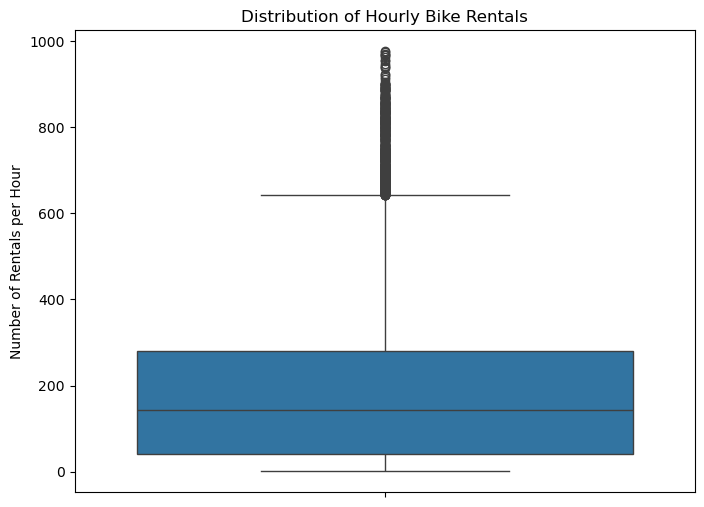

In [10]:
plt.figure(figsize = (8,6))
sns.boxplot(y = df["cnt"])
plt.title("Distribution of Hourly Bike Rentals")
plt.ylabel("Number of Rentals per Hour")
plt.show()


The boxplot suggests positive skewness, as the upper whisker is longer and outliers appear above it. I will create a histogram to examine the distribution of hourly bike rentals and identify the most frequent rental ranges.

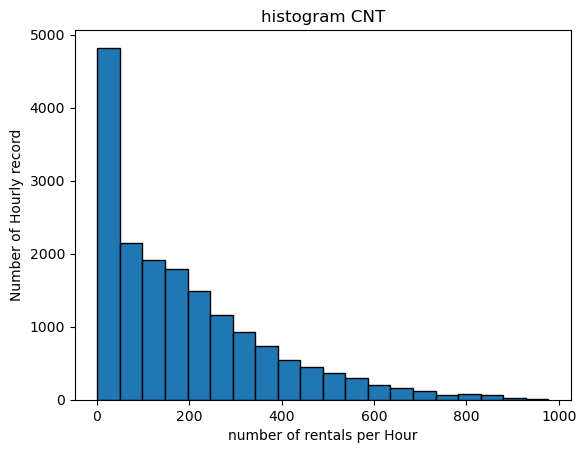

In [11]:
plt.hist(df["cnt"], bins=20, edgecolor="black")
plt.title("histogram CNT")
plt.xlabel("number of rentals per Hour")
plt.ylabel("Number of Hourly record")
plt.show() 

Of the 17,379 hourly records, approximately 4,800 show between 1 and 50 rentals per hour, based on a visual estimate from the histogram. Hours with fewer rentals are more frequent than hours with higher rental counts. This is consistent with what the boxplot suggested: the distribution has a tail extending towards higher values and is therefore positively skewed.

In [12]:
#como cambia el promedio de alquiler a lo largo del dia ? deberia trabajar con Hr y cnt cantidad total de alquiler y sacar el mean 
df.groupby("hr")["cnt"].mean()

hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64

During the period analysed, 17:00 had the highest average number of bike rentals, with approximately 461 rentals per recorded hour.

guardo los datos de mean para poder trabajar el grafico lineal que necesito. utilizo .index para hr y .values 
para los promedios de cnt 

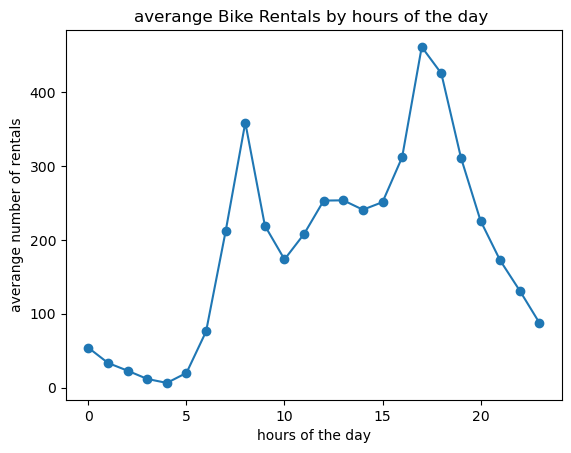

In [13]:
#definimos eje X he Y
mean_hr = df.groupby("hr")["cnt"].mean()
plt.plot(mean_hr.index, mean_hr.values, marker="o")

plt.title("averange Bike Rentals by hours of the day ")
plt.xlabel("hours of the day")
plt.ylabel("averange number of rentals")
plt.show()

como podemos observar el grafico nos muestras a que hora del dia se observa una renta mayor de bibicletas. podriamos interpretar que el promedio
comienza a aumentar a partir de las 5 de la mañana y alcanza un pico maximo a las 8 de la mañana esto puede deberse al desplazamiento matutino hacia el trabajo o al estudio. sin emabargo Pero el promedio mayor aparece a las 17:00 lo que puede deberse a al desplazamiento de regreso. 

ahora para comenzar a trabajar con binomial distribution me hare la primera pregunta: 
-en 20 dias comparables, ¿que probabilidad hay de que en almenos 12, 
se supere sierta cantidad de alquiler a las 17:00

para calcular binomial distribution, primero tengo que definir que probabilidad de alquileres consideraria un exito en mi proyecto.
    en este caso definire un exito ocurre cuando los alquileres a las 17:00 superan la media historica de las 17:00 del grupo selecionado 
    

In [14]:
#comienzo calculando la media del grupo (17:00) que voy a estudiar
selected = df[(df["hr"]==17) & (df["workingday"]==1)]
threshold = selected["cnt"].mean()
print("threshold:",threshold)
    


threshold: 525.2905811623247


In [15]:
#525 es el promedio de los dias laborales, esto quiere decir que si tengo 526 es exito y si tengo 525 alquileres o menos es fracaso 
#ahora guiandome por el ejercicio del profesor (distribution_sep2025) aparece que para sacar successfull debo hacer la siguiente formula

In [16]:
success= (selected["cnt"]>threshold).sum()
print("number of success:",success)

number of success: 267


ahora que tenemos el numero de sucesos (267) se necesita calcular P = probabilidad estimada con registros hitoricos.

    p = valid selected observations above the  threshold / total valid selected observations 

In [25]:
total_records = selected["cnt"].count()
p_estimate = success / total_records
print("total records:",total_records)
print("estimated p:",p_estimate)

total records: 499
estimated p: 0.5350701402805611


p = 267 / 499 = 0,53507 

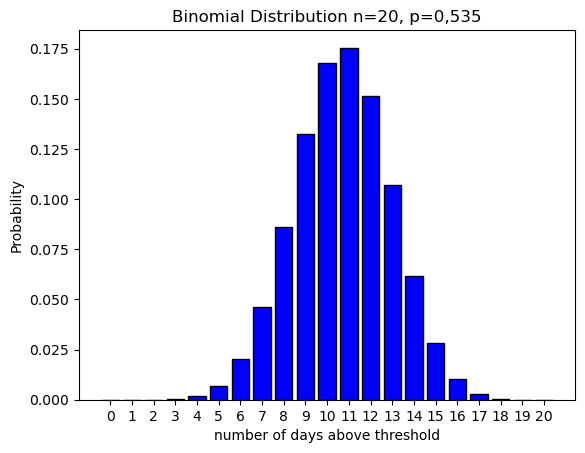

In [26]:
#importamos binom para poder calcular la probabilidad 
from scipy.stats import binom

n = 20
p = p_estimate
k = np.arange(0,n + 1)

#binomial probability mass function
binom_pmf = binom.pmf(k,n,p)

#plot the binomial distribution

plt.bar(k, binom_pmf, color="blue", edgecolor="black")
plt.title("Binomial Distribution n=20, p=0,535")
plt.xlabel("number of days above threshold")
plt.ylabel("Probability")
plt.xticks(k)
plt.show()

como podemos observar el eje x muestra los numeros de dias entre 20 que superan el umbral
en el eje Y nos muestra exactamente la probabilidad de obtener exactamente esa cantidad de dias y la barra mas alta esta en 11 esto nos indica que obtener 11 dias exitosos es el resultado mas probable con un 17,5%. 
para mi pregunta en especifo "al menos 12 dias" necesito sumar las probabilidades de la 12 a la 20.  

In [28]:
probability = binom.sf(11,n,p)
print("probability of at least 12 successes",probability)

probability of at least 12 successes 0.3624502370270213


uno de los requisitos del profesor que aumentar el numero de intentos y numero de simulaciones, ocupare:
n 20 - 50 - 100
y diferente simulaciones (100 - 10.000)


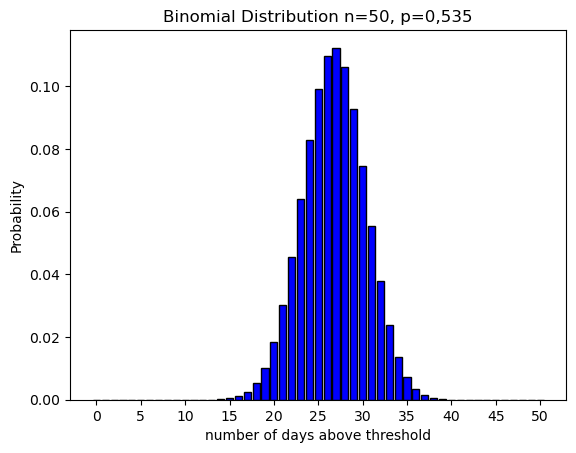

In [29]:
n = 50
p = p_estimate
k = np.arange(n + 1)

#binomial probability mass function
binom_pmf = binom.pmf(k,n,p)

#plot the binomial distribution

plt.bar(k, binom_pmf, color="blue", edgecolor="black")
plt.title("Binomial Distribution n=50, p=0,535")
plt.xlabel("number of days above threshold")
plt.ylabel("Probability")
plt.xticks(np.arange(0,n+1,5))
plt.show()

en este analisis podemos inferir que un dia exitoso laborable que registre 526 alquileres o mas durante las hora de las 17:00, superando la media historical del grupo de 525,29 aquileres. al comparar las distribuciones de 20 y 50 dias, los resultados se concentran alrededor de 11 y 27 dias exitosos, respectivamente. esto quiere decir que al considerar mas dias, aumenta el numero esperado de dias que superan el umbral, mientras que la probabilidad de exito de cada dia se mantiene aproximadamente en 53,5% estas cantidades no estan garantizadas: son resultados del modelo binomial 

igual que para binomial me debo planter una pregunta. segun el modelo poisson cual es la probabilidad de registrar exactamente 550 alquileres entre las 17:00 y las 18:00 de un dia laboral?

para evaluar si el modelo poisson es adecuado, comparamos la media y la varianza 

In [30]:
selected["cnt"].agg(["mean","var"]) #la variance indica que tan dispersos o alejados estan los datos respecto a la media.

mean      525.290581
var     52331.616196
Name: cnt, dtype: float64

con este resultado podemos inferir que la variance es mucho mayor que la media lo cual indica sobredispersion: los alquileres varian 
mucho mas de lo que supone un modelo Poisson simple. si utilizo lambda = 525,29 poisson concentrara demasiado sus probabilidades alrededor de la media.

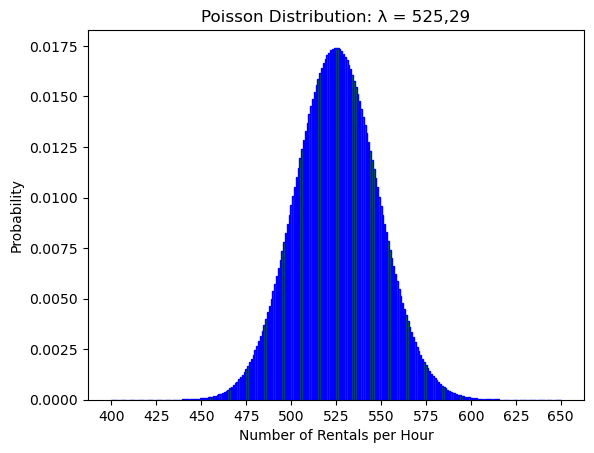

In [44]:
from scipy.stats import poisson

lambda_value = selected["cnt"].mean()  # Average number of events in the interval
k = np.arange(400,651)  # Number of possible events (400 to 650)

# Poisson probability mass function (pmf)
poisson_pmf = poisson.pmf(k, lambda_value)

# Plot the Poisson distribution
plt.bar(k, poisson_pmf, color='green', edgecolor='blue')
plt.title('Poisson Distribution: λ = 525,29')
plt.xlabel('Number of Rentals per Hour')
plt.ylabel('Probability')
plt.xticks(np.arange(400,651,25))
plt.show()

analizare la barra de alquilere 550 para ver cual es la probabilidad de tener esa cantidad de alquileres enre las 17:00 y 18:00  

In [37]:
poisson.pmf(550, lambda_value)

0.009596999290188566

como podemos observar el modelo poisson presenta una forma aproximadamente normal debido al elevado valor de "lambda". sin embago, supone una varianza de 525,29 mientras que la varianza observada es de 52.331,62. Esto indica sobredispersion. los recuentos reales presentas mas variabilidad de las que represnta el modelo.la probabilidad de registrar exactamente 550 alquileres entre las 17:00 y 18:00 de un dia laboral, es aproximadamente del 0.96% segun el modelo Poisson. este resultado debe interopretarse con cautela, porque el modelor representa una variabilidad mucho menor que la observada en los datos reales.

ahora que Poisson esta desarrollado podemos analizar: ¿el modelo concentra los alquileres en un intervalo mas estrecho que los datos observados?

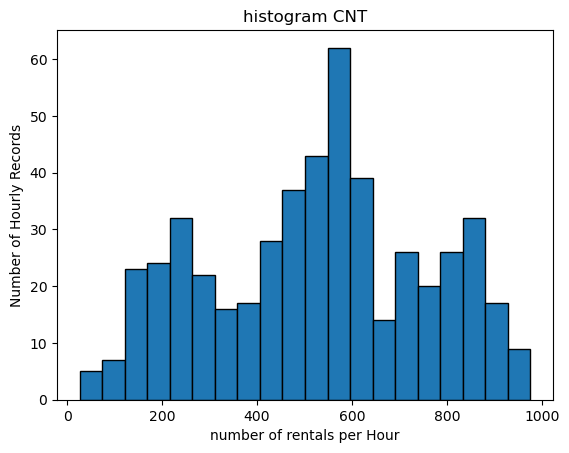

In [43]:
plt.hist(selected["cnt"], bins=20, edgecolor="black")
plt.title("histogram CNT")
plt.xlabel("number of rentals per Hour")
plt.ylabel("Number of Hourly Records")
plt.show() 

como podemos observar en nuestro nuevo histogran en torno a los datos reales de las 17:00 en dias laborales, la comparacion revela que los recuentos abarcan aproximadamente desde una decenas hasta casi 1000 alquileres. a su vez el modeo Poisson concentra casi toda su probabilidad en un intervalo mucho mas estrecho, al rededor de 525 y por su parte el histogram presenta varios picos visibles; su forma es mas irregular que la del modelo. Esta diferencia respalda la sobredispersion detectada al comparar la media y la varianza. 

analizare poisson con otros valores para ver la diferencia y comparare ocupare lambda 5 y 20 

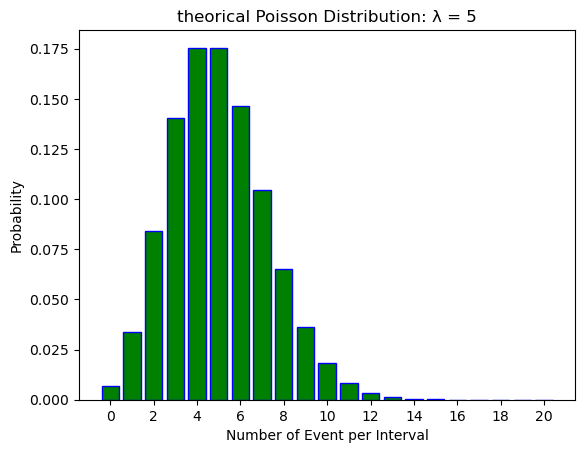

In [47]:
lambda_value = 5 #theorical example 
k = np.arange(0, 21)  


poisson_pmf = poisson.pmf(k, lambda_value)


plt.bar(k, poisson_pmf, color='green', edgecolor='blue')
plt.title("theorical Poisson Distribution: λ = 5")
plt.xlabel('Number of Event per Interval')
plt.ylabel('Probability')
plt.xticks(np.arange(0,21,2))
plt.show()

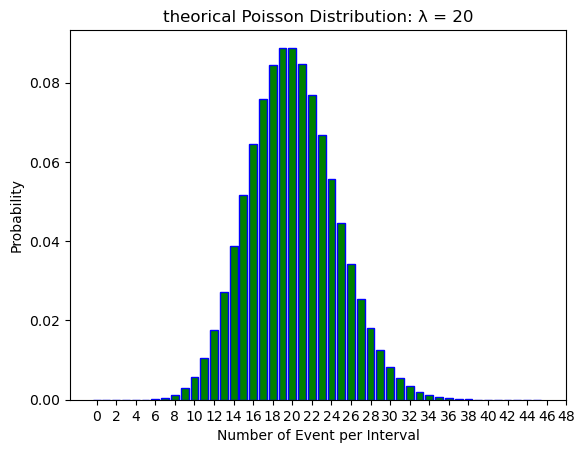

In [51]:
lambda_value = 20 #theorical example 
k = np.arange(0,46)  


poisson_pmf = poisson.pmf(k, lambda_value)


plt.bar(k, poisson_pmf, color='green', edgecolor='blue')
plt.title("theorical Poisson Distribution: λ = 20")
plt.xlabel('Number of Event per Interval')
plt.ylabel('Probability')
plt.xticks(np.arange(0,50,2))
plt.show()

decidi ocupar valores menores de lamda para observar las diferencias entre los gradicos con mayor claridad con lambda=5, la distribucion tiene una simetria hacia la derecha.
    con lambda= 20 adquiere una forma mas simetrica, en cambio con lambda= 525,29, la distribucion poisson es aproximadamente simetrica y su forma se aproxima a la normal
esta comparacion modifica solo la tasa media lambda, no el tamaño de la muestra y no elimana la sobredispersion observada en los datos reales

In [54]:
lambda_value = selected["cnt"].mean()

Distribucion Normal 

la distribucion normal la realizare a partir de temp  ya que es una medicion continua y a su vez, tiene sentido en el contexto del alquiler de bicicleta 

In [55]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [57]:
df["temp"].describe()

count    17379.000000
mean         0.496987
std          0.192556
min          0.020000
25%          0.340000
50%          0.500000
75%          0.660000
max          1.000000
Name: temp, dtype: float64

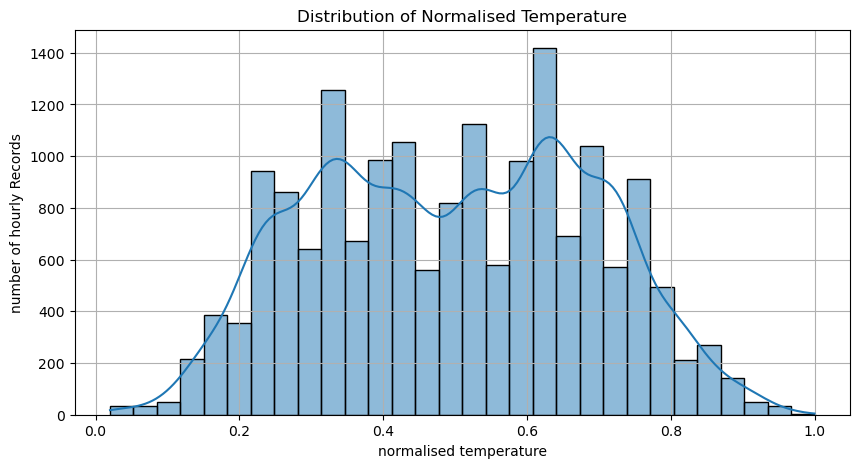

In [61]:
 #Plot normal distribution using temp
plt.figure(figsize=(10, 5))
sns.histplot(df['temp'], bins=30, kde=True)
plt.title("Distribution of Normalised Temperature")
plt.xlabel('normalised temperature')
plt.ylabel('number of hourly Records')
plt.grid()
plt.show()

examine la distribucion de la temperatura normalizada mediante un histogram y observe dos elevaciones amplias entre 0,35 y 0.65 en lugar de una unica campana clara. para evaluar si una aproximacion normal es razonable, utilizare un grafico Q-Q como se explica en el material del profesor (normal distribution handbook) 
este grafico permite observar si los valores sigues aproximadamente una linea recta o presentan desviacion sistematica.

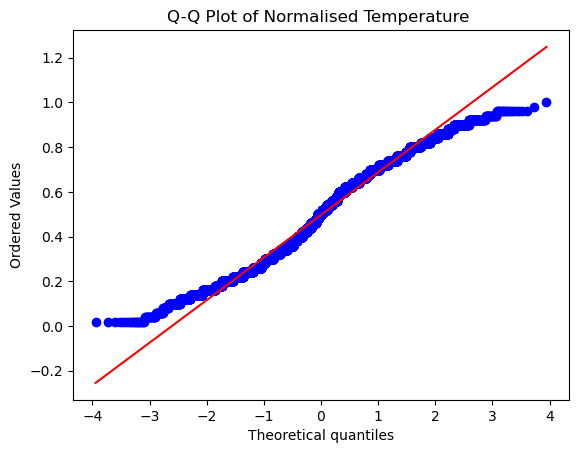

In [63]:
from scipy import stats

stats.probplot(df["temp"].dropna(), dist='norm', plot=plt)
plt.title('Q-Q Plot of Normalised Temperature ')
plt.show()


despues de examinar el grafico Q-Q, observo que los puntos se acercan a la linea de referencia en la parte central pero representa desviacion clara en los extremos 
esto indica que la aproximacion nomarl tiene limitaciones especialmente en la cola de la distribucion 

under a normal model, what is the probability that normalised temperature fall abetween two chosen limits, and how does this compare with the proportion observed in the dataset?

para responder a mi pregunta ocupare mi primer y tercer quartiles (Q1 , Q3)

In [72]:
from scipy.stats import norm 
mean = df["temp"].mean()
std = df["temp"].std()

lower = 0.34
upper = 0.66

model_probability = (norm.cdf(upper, loc = mean, scale = std)-norm.cdf(lower, loc = mean, scale = std))

print("model probability:",model_probability)
print("model probability (%):", model_probability * 100)

model probability: 0.5939274357610805
model probability (%): 59.39274357610805


bajo una aproximacion normal la probabilidad estimada de que la temperatura normalizada se encuentre entre 0,34 y 0,66 es del 59% este resultado
debe compararse con la proporcion observada para evaluar la aproximacion


nuestro segundo paso es calcular la proporcion real de registros entre esos mismos limites, para calcularla con el 59,39% del modelo 


In [74]:
observed_proportion = df["temp"].between(lower,upper).mean()
print("observed proportion (%):", observed_proportion * 100)

observed proportion (%): 54.83629667990103


el modelo observado sobreestima la proporcion de temperatura dentro del intervalo de 0,34 a 0,66
es decir el modelo asigna mas probabilidades a ese intervalo de la que muestra datos reales, esto evidencia una limitacion de la aproximidad normal en ese intervalo,
coherente con las diferencias que mostraron los graficos, no se obtiene exactamente 50% ya que inclui ambos limites y existen temperaturas repetidas en los cuartiles

binomial: para aplicar la distribucion binomial, plantee que probabilidad existe de que al menos 12 de 20 dias laborales comparables registren 526 alquileres o mas a las 17:00, aunque exactamente 11 dias exitosos es el resultado individual mas probable, con aproximadamente 17,5% la probabilidad de obtener al menos 12 dias exitosos es del 36,25% bajo los supuestos del modelo

poisson: para evaluar el modelo Poisson compare la media y la varianza de los alquileres a las 17:00 en dias laborales. la varianza fue mucho mayor que la media lo que indico sobredispersion. estime lambda mediante la media de 525,29 alquileres por hora. El modelo presento una forma aproximadamente normal debido al elevado valor de lambda; sin embargo represento una variable mucho menos que la observada en los datos reales

normal: para evaluar una aproximacion normal seleccione temp, una variable continua que describe la temperatura normalizada registrada junto con los alquileres. el histogram mostro dos elevaciones amplias al rededor de 0,35 y 0,65 en lugar de una unica campana clara. utilice un grafico Q-Q y observe que los puntos de acercaban a la linea de referencia en parte de la zona central, pero se desviaban en los extremos. Esto señalo limitaciones de la aproximacio, sin embargo el modelo estimo un 59,39% entre 0,34 y 0,66, frente al 54,84% observado; sobreestimo la proporcion en aproximadamente 4,56 puntos porcentuales  